# Visualizing Next-Token Predictions

## Introduction

This reference notebook uses the OpenAI Chat Completions API to generate a short response and inspect the model's next-token predictions. The `visualizer.py` helper requests token log probabilities, converts them to probabilities, and displays the selected token alongside alternative candidates in a directed graph.

By the end, you should be able to:
- Explain how a model's selected token and alternative next-token candidates are represented.
- Read the per-token probabilities shown in the graph.
- Distinguish a local next-token probability from the probability or confidence of an entire response.

## Requirements

- Run this notebook from its folder so the adjacent `visualizer.py` module can be imported.
- Configure `OPENAI_API_KEY` in the environment or in a `.env` file in the project. Never put a real key in a notebook cell or commit it.
- The model request requires network access and may incur API charges. The visualization itself can be tested offline with sample predictions.

## 1. Load the helper module

Import the project-local functions that retrieve token predictions, build the graph, and render it.

In [ ]:
# The helper lives beside this notebook. Reload it to pick up local edits.
import importlib
import visualizer

importlib.reload(visualizer)

from visualizer import TokenPredictor, create_token_graph, visualize_predictions

print(f"Loaded helpers from: {visualizer.__file__}")

## 2. Confirm API configuration

The helper loads values from `.env` when imported. This check confirms that a key is present without printing it; it does not make an API request.

In [ ]:
import os

# Check that the key is available without displaying or copying its value.
if not os.getenv("OPENAI_API_KEY"):
    raise RuntimeError(
        "OPENAI_API_KEY is not set. Add it to your environment or a .env file."
    )

print("OPENAI_API_KEY is configured.")

## 3. Generate and visualize predictions

This cell makes a real API request. `predict_tokens` streams the response and records the selected token plus log probabilities for alternatives. The graph then shows the chosen path and other likely candidates at each step.

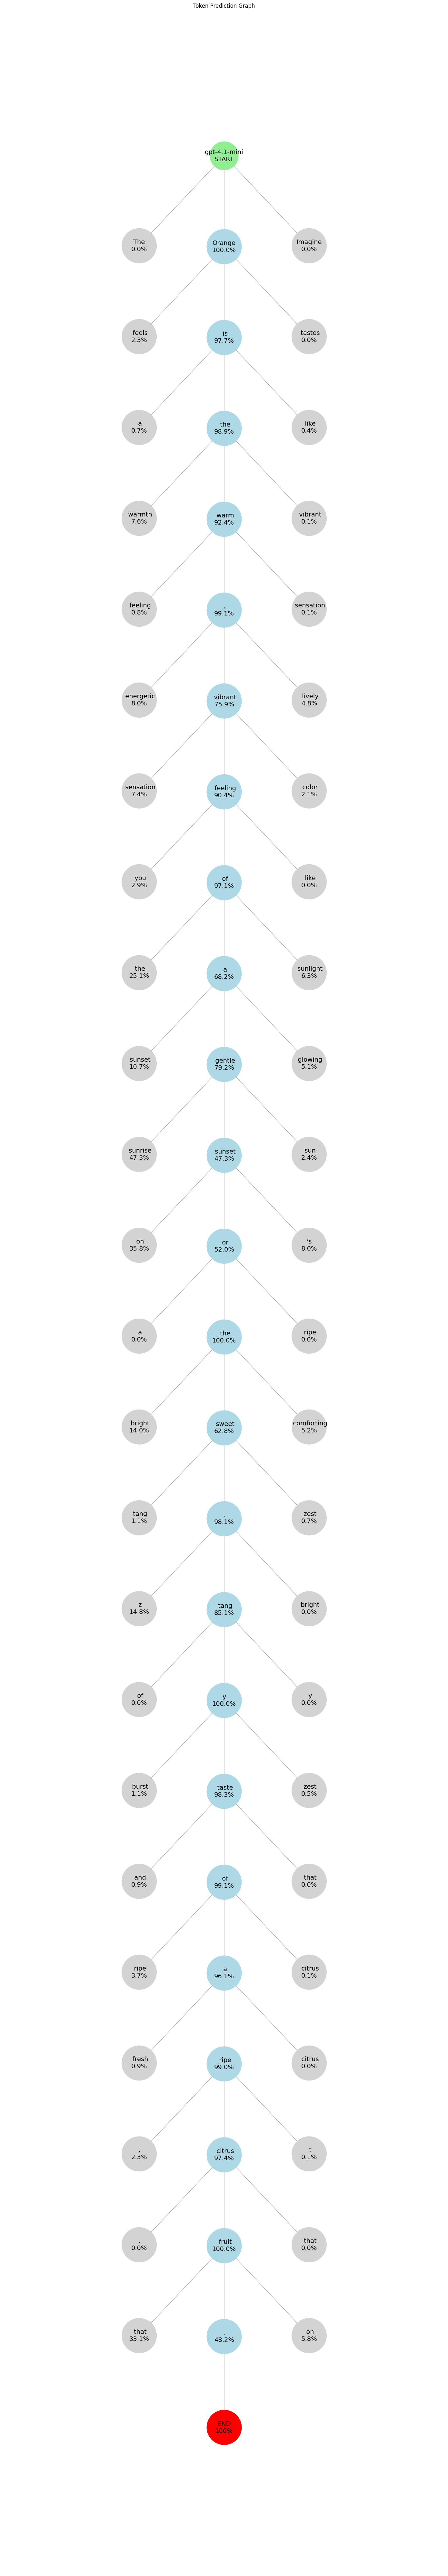

In [3]:
# Use a short prompt so the generated token path is easy to inspect.
message = "In one sentence, describe the color orange to someone who has never been able to see."
model_name = "gpt-4.1-mini"

# Stream the response and collect each selected token with its alternatives.
predictor = TokenPredictor(model_name)
predictions = predictor.predict_tokens(message)
if not predictions:
    raise RuntimeError("The model returned no token predictions to visualize.")

# Build and display the directed graph of the selected path and alternatives.
graph = create_token_graph(model_name, predictions)
plot = visualize_predictions(graph)
plot.show()

## Reading the graph

- **Green `START`** marks the beginning of generation and identifies the model.
- **Blue nodes** are the tokens selected along the generated response.
- **Gray nodes** are alternative candidates at that generation step; the helper displays the top two alternatives.
- **Red `END`** marks the end of the selected path.
- Percentages are per-step token probabilities, computed from log probabilities. They are not a probability or confidence score for the complete response.

## Summary and conclusion

The workflow is: provide a prompt, request a streamed completion with log probabilities, then turn the selected tokens and alternatives into a graph. The graph makes the model's local next-token choices easier to inspect, but it does not explain why a token was selected or measure the quality of the full answer.

To reuse this notebook, change `message` and, if desired, `model_name`. The `predict_tokens` method also accepts `max_tokens` to control the generation limit. Keep API credentials out of notebook source and remember that running the request may incur charges.